# 02 - Exploratory Data Analysis (EDA)

The graphs summarize observed purchase frequency, basket distributions, temporal ordering patterns and exploratory numeric correlations. **All supplied outputs use real Instacart orders (a documented 30,000-order sample).**

In [11]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'scripts').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
# Original Instacart, 30,000 reproducibly selected prior orders.

DATA_MODE = 'real'
print('DATA MODE:', DATA_MODE.upper(), '|', 'REAL INSTACART SAMPLE' if DATA_MODE == 'real' else 'SYNTHETIC DEMO')

DATA MODE: REAL | REAL INSTACART SAMPLE


## Review seven reproducible charts

The charts are generated by `scripts/eda.py` and saved in `images/<mode>/`. Interpretation notes and summary metrics are saved in `reports/<mode>/`.

Top-item frequencies are counts, not sales or prices.

In [12]:
from IPython.display import display, Image, Markdown
import json

image_dir = ROOT / 'images' / DATA_MODE
report_dir = ROOT / 'reports' / DATA_MODE

metrics = json.loads((report_dir / 'eda_metrics.json').read_text())

print('Data source: original Instacart sample')
print('Baskets:', metrics['analyzed_baskets'])
print('Mean basket size:', round(metrics['mean_basket_size'], 2))

Data source: original Instacart sample
Baskets: 30000
Mean basket size: 10.08


## Product frequency and basket size
Products are counted by observed purchase line; basket size is distinct products per nonempty order. We use a histogram and boxplot to investigate the **distribution** and plausible long tail.

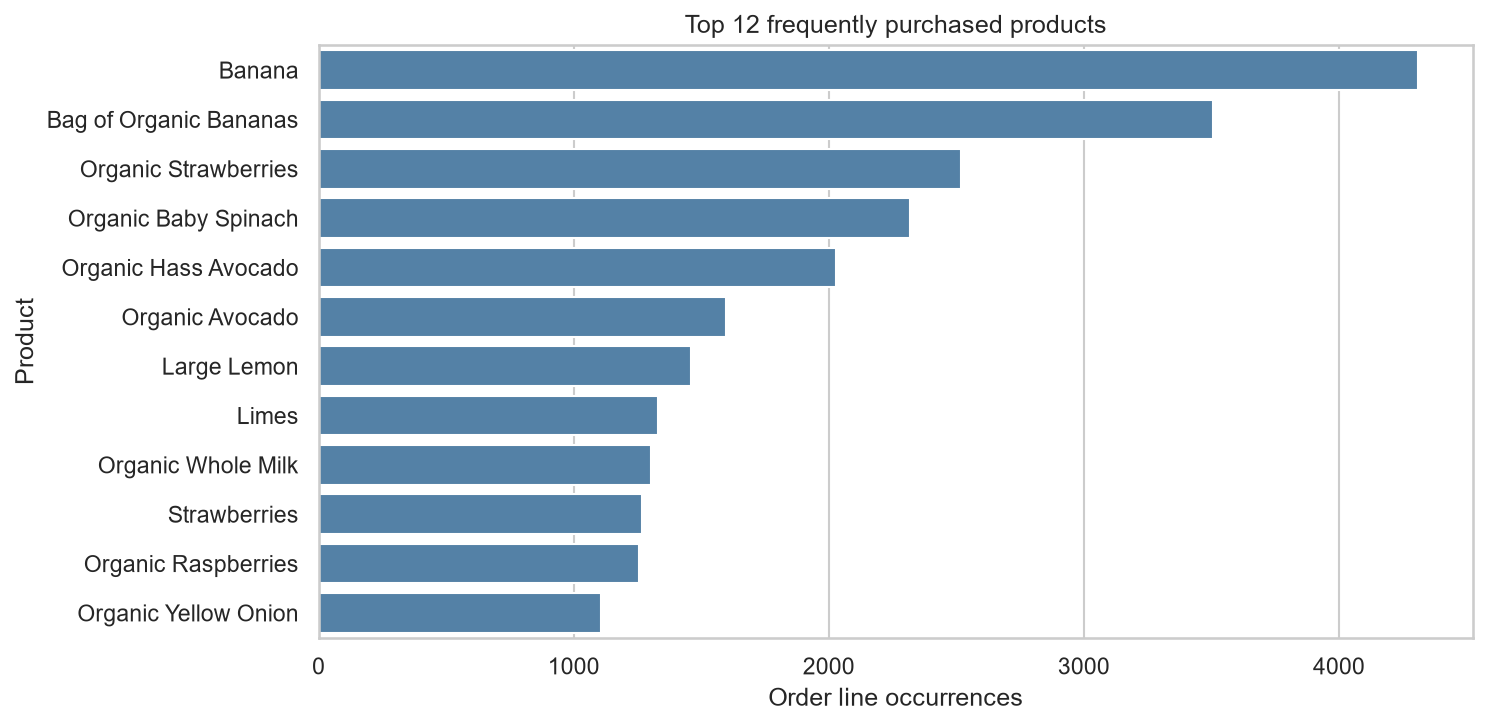

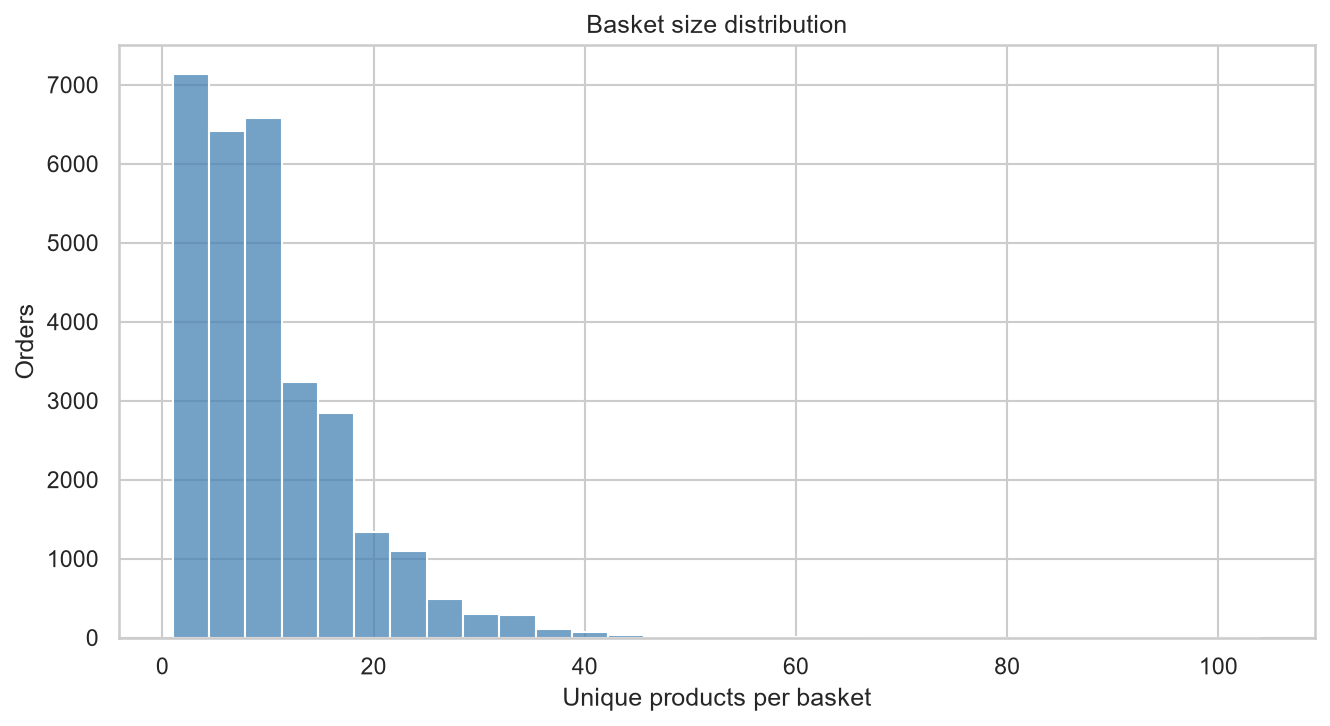

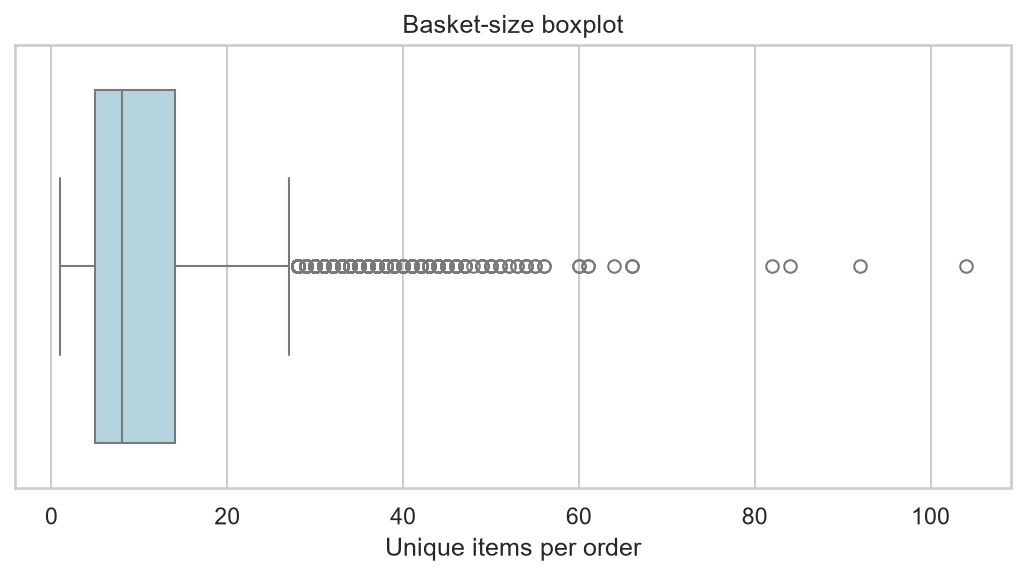

In [8]:
for fname in ['01_top_products.png','02_basket_sizes.png','06_basket_boxplot.png']:
    display(Image(filename=str(image_dir/fname),width=650))

## Shopping time and department patterns
The day code is **0–6**. We do not claim a specific weekday mapping without verifying source documentation.

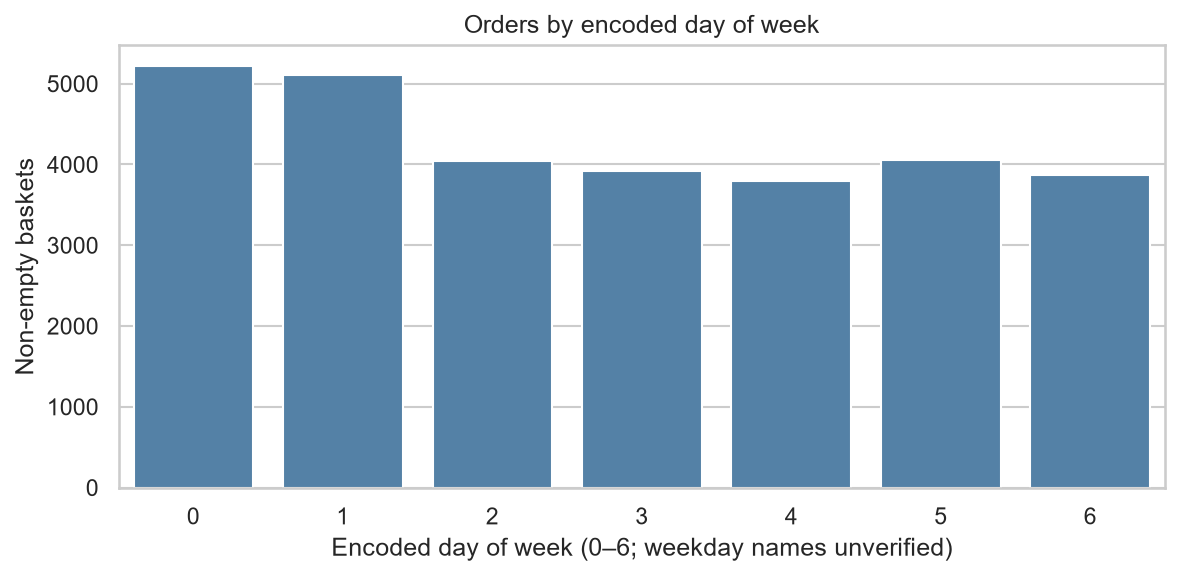

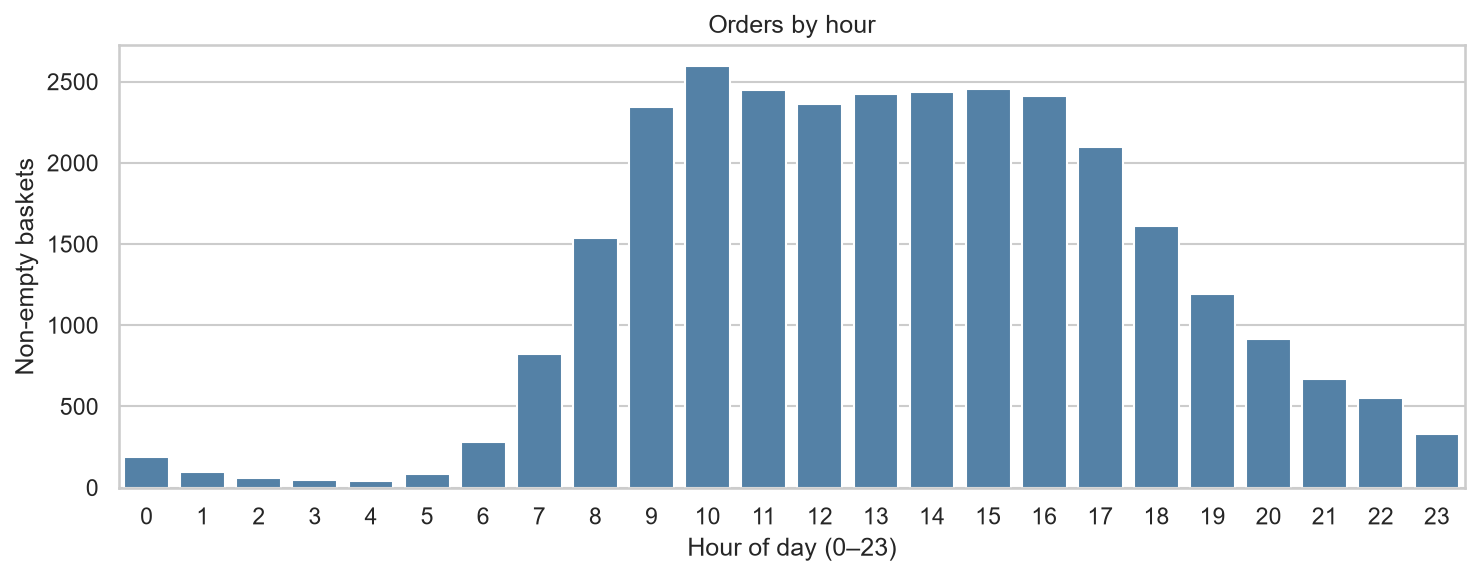

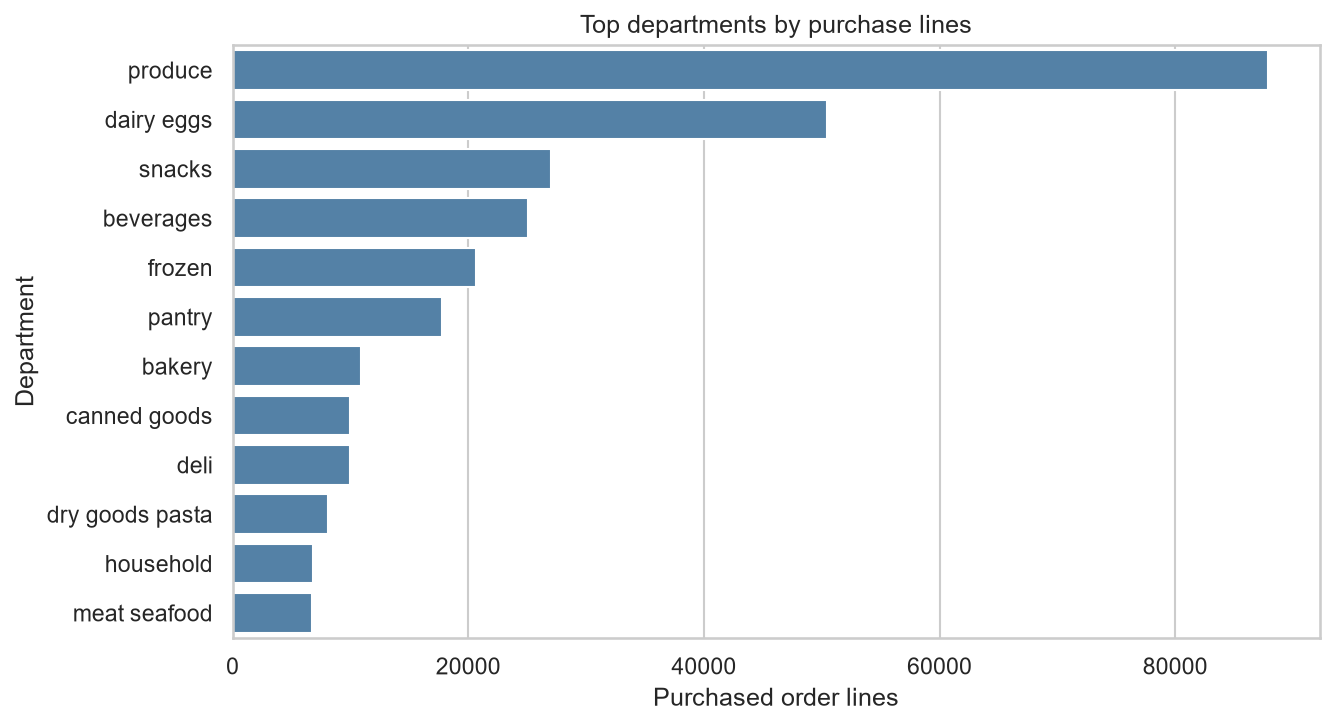

In [9]:
for fname in ['03_order_day.png','04_order_hour.png','05_departments.png']:
    display(Image(filename=str(image_dir/fname),width=650))

## Numeric correlations
These are descriptive, observational Pearson correlations of numeric measures. We exclude categorical product IDs; repeated line-level rows prevent naive independence assumptions. These are **not** product association rules.

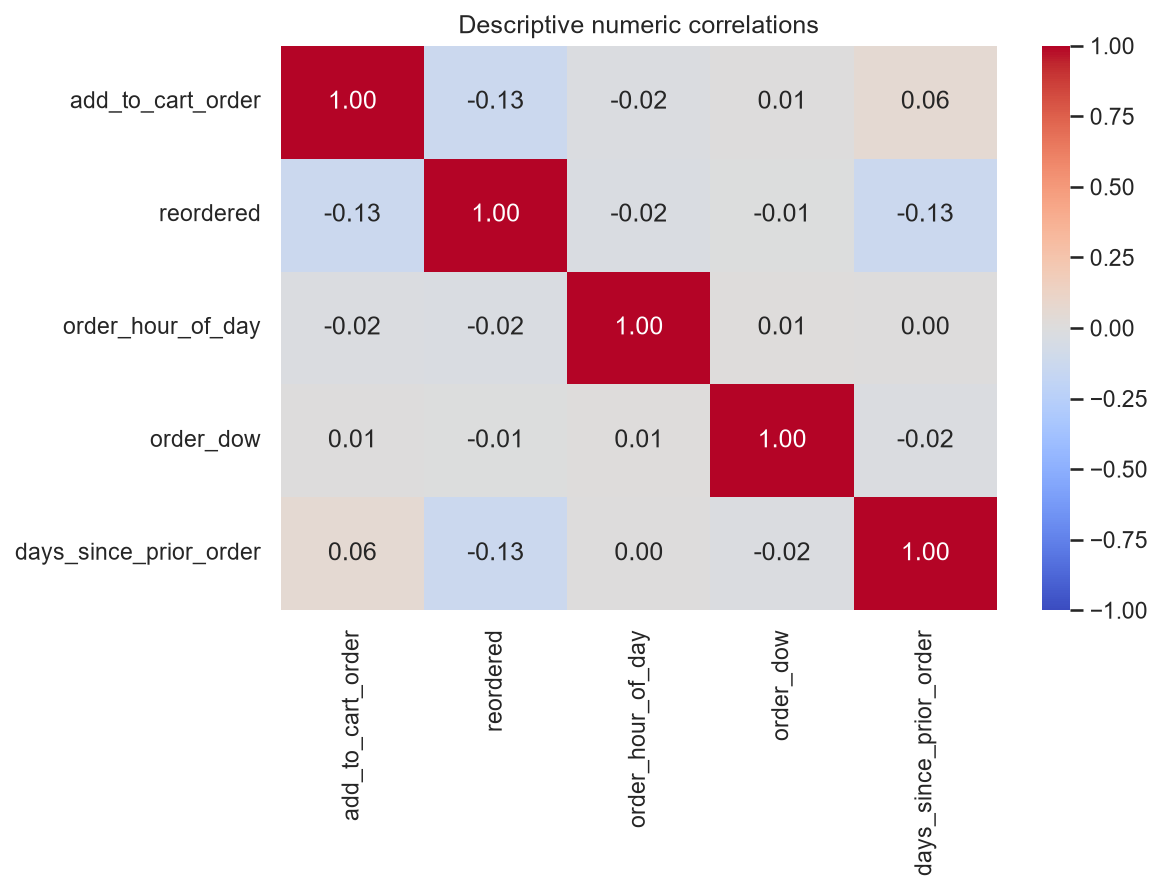

# REAL INSTACART SAMPLE — PHASE 1 FINDINGS

- 30,000 non-empty prior baskets were analyzed.
- Mean basket size: 10.08 unique products; median: 8.
- Most frequent product: Banana (4,310 order lines).
- Most frequently represented department: produce (87,854 order lines).
- Most common encoded day: 0; peak order hour: 10:00.
- Reorder flag prevalence across cleaned product purchase lines: 59.2%. This is not a classification target for Phase 1.

## Visualization explanations

- **01_top_products.png**: Products with the largest number of observed purchased order lines; occurrence does not measure revenue.
- **02_basket_sizes.png**: Shows whether typical orders contain few or many unique items; high values may be genuine, not errors.
- **03_order_day.png**: Shows ordering frequency by dataset day code 0–6; original data does not explicitly define calendar weekday names.
- **04_order_hour.png**: Shows peak ordering hours in the chosen sample, useful for browsing trends.
- **05_departments.png**: Higher counts indicate more frequently purchased items from a department, not necessarily more spending.
- **06_basket_boxplot.png**: Points beyond whiskers are potentially interesting large baskets; do not automatically remove them.
- **07_numeric_correlations.png**: Exploratory linear correlations only; order rows repeat across items and this does not imply causal relationships.

## Modeling readiness (Phase 2)

- Use cleaned `baskets.csv` and item ID fields for basket-based association mining.
- Do not scale IDs. If evaluating recommendations, split data without leaking held-out baskets.
- Category frequencies are imbalanced; report top-heavy product popularity and evaluate across popularity tiers.
- These are descriptive results; no prediction or association-rule mining occurs in Phase 1.


In [10]:
display(Image(filename=str(image_dir/'07_numeric_correlations.png'),width=650))
display(Markdown((report_dir/'INSIGHTS.md').read_text(encoding='utf8')))